In [1]:
import pandas as pd

# Читаем сохранённый файл с данными, делая первый столбец индексом DataFrame
df_work = pd.read_csv('wells_extracted_data.csv', sep=';', index_col=0, encoding='utf-8-sig')

# Проверяем результат
print("Размерность таблицы:", df_work.shape)

Размерность таблицы: (39, 65)


In [2]:
# Смотрим информацию по датасету
df_work.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39 entries, A to EW
Data columns (total 65 columns):
 #   Column                                                     Non-Null Count  Dtype  
---  ------                                                     --------------  -----  
 0   X                                                          39 non-null     float64
 1   Y                                                          39 non-null     float64
 2   Heff                                                       39 non-null     float64
 3   dT_Ju1                                                     39 non-null     float64
 4   Envelope_Modulated_Phase_a8b4_raw_amplitude_sum_abs_diff   39 non-null     float64
 5   Envelope_Second_Derivative_a8b4_raw_amplitude_max          39 non-null     float64
 6   Envelope_Second_Derivative_a8b4_raw_amplitude_min          39 non-null     float64
 7   Envelope_Second_Derivative_a8b4_raw_amplitude_rms_average  39 non-null     float64
 8   Envelope_Time_Der

In [3]:
# Очень часто параметры пластов в точках скважин имеют очень слабые корреляционные связи
# с атрибутами сейсмической записи. Поэтому сначала посмотрим коэффициенты корреляции
# свойства пласта с атрибутами. Так как свойства пласта определяются обстановками,
# в которых пласт формировался, в данном случае это прибрежно-морские обстановки,
# то должна существовать пространственная зависимость изменения свойств. Поэтому
# в комплект карт атрибутов дополнительно включены гриды координат X и Y.

pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)

# Считаем корреляцию Пирсона с Heff (исключая Heff сам с собой)
columns_to_exclude = ['Heff', 'X', 'Y']
correlations = df_work.drop(columns=columns_to_exclude).corrwith(df_work['Heff'], method='pearson')

# Превращаем в DataFrame
df_corr = correlations.to_frame(name='Pearson_R')

# Сортируем по убыванию абсолютного значения коэффициента корреляции, не меняя знаки в таблице
df_corr_sorted = df_corr.sort_values(by='Pearson_R', ascending=False, key=abs)

# Выводим итоговую таблицу
print("Таблица корреляции с Heff (отсортировано по модулю коэффициента корреляции):\n")
print(df_corr_sorted)


Таблица корреляции с Heff (отсортировано по модулю коэффициента корреляции):

                                                           Pearson_R
Grid_Y                                                      0.725633
dT_Ju1                                                     -0.603280
Ju1_a14b4_average_freq_sum_abs_diff                         0.455525
Ju1_a14b4_derivative_inst_amp_sum_negative                 -0.412690
Ju1_a14b4_amp_weighted_cos_phase_rms_average                0.399409
Ju1_a14b4_quadrature_trace_max                              0.375554
Ju1_a14b4_2nd_derivative_sum_positive                       0.368221
Ju1_a14b4_derivative_inst_amp_mean                         -0.357828
Ju1_a14b4_amp_weighted_phase_sum_abs_diff                   0.332973
Ju1_a14b4_filt_15_20_25_30_mean                            -0.328564
Ju1_a14b4_2nd_derivative_mean                               0.323746
Ju1_a14b4_filt_55_60_65_70_mean                            -0.316830
Ju1_a14b4_integrated_abs_

In [4]:
# Для дальнейшей работы отберём признаки, которые имеют значимую корреляционную связь

from scipy.stats import pearsonr

target = df_work['Heff']
columns_to_exclude = ['Heff', 'X', 'Y']
features = df_work.drop(columns=columns_to_exclude)

valid_features = []

for col in features.columns:
    # Считаем корреляцию и p-value, игнорируя NaN
    mask = features[col].notna() & target.notna()
    if mask.sum() > 2: # Для корреляции нужно как минимум 3 точки
        r_value, p_value = pearsonr(features[col][mask], target[mask])
        
        # Оставляем признак только если связь статистически подтверждена
        if p_value < 0.05: 
            valid_features.append(col)
            print(f"Признак '{col}': R = {r_value:.2f}, p-value = {p_value:.4f} -> ОСТАВЛЯЕМ")
        else:
            print(f"Признак '{col}': R = {r_value:.2f}, p-value = {p_value:.4f} -> ИСКЛЮЧАЕМ (случайная связь)")

# Пересобираем датафрейм только со значимыми признаками
df_filtered = df_work[columns_to_exclude + valid_features]


Признак 'dT_Ju1': R = -0.60, p-value = 0.0000 -> ОСТАВЛЯЕМ
Признак 'Envelope_Modulated_Phase_a8b4_raw_amplitude_sum_abs_diff': R = -0.07, p-value = 0.6516 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Envelope_Second_Derivative_a8b4_raw_amplitude_max': R = -0.05, p-value = 0.7752 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Envelope_Second_Derivative_a8b4_raw_amplitude_min': R = 0.15, p-value = 0.3597 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Envelope_Second_Derivative_a8b4_raw_amplitude_rms_average': R = -0.10, p-value = 0.5331 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Envelope_Time_Derivative_a8b4_raw_amplitude_mean': R = -0.23, p-value = 0.1524 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Envelope_Time_Derivative_a8b4_raw_amplitude_sum_abs_diff': R = -0.04, p-value = 0.8259 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Grid_X': R = -0.25, p-value = 0.1180 -> ИСКЛЮЧАЕМ (случайная связь)
Признак 'Grid_Y': R = 0.73, p-value = 0.0000 -> ОСТАВЛЯЕМ
Признак 'Inversion_a8b4_raw_amplitude_mean': R = 0.13, p-value = 0

In [5]:
df_filtered

,Heff,X,Y,dT_Ju1,Grid_Y,Ju1_a14b4_2nd_derivative_mean,Ju1_a14b4_2nd_derivative_sum_positive,Ju1_a14b4_amp_weighted_cos_phase_rms_average,Ju1_a14b4_amp_weighted_phase_sum_abs_diff,Ju1_a14b4_average_freq_sum_abs_diff,Ju1_a14b4_derivative_inst_amp_mean,Ju1_a14b4_derivative_inst_amp_sum_negative,Ju1_a14b4_filt_15_20_25_30_mean,Ju1_a14b4_filt_55_60_65_70_mean,Ju1_a14b4_quadrature_trace_max
WellName,,,,,,,,,,,,,,,
A,5.60,321634.0,786222.0,26.872099,786222.222222,-28.761113,2204.756281,1561.631359,8.897349e+05,1.615648,49.314086,-1339.154967,-1036.903779,-45.904246,4061.763959
B,3.50,324359.0,773299.0,42.185217,773295.652174,7.658794,1194.423650,885.148931,6.197301e+05,0.709090,-31.001144,-738.755728,-39.397221,19.096737,1128.302966
C,3.81,330115.0,776511.0,37.852820,776519.230769,-31.832004,1323.590958,1735.331404,9.258057e+05,2.587898,-129.868338,-1212.492854,120.519822,97.102006,781.075785
D,0.00,332670.0,782301.0,29.674782,782300.000000,13.526136,1873.106378,1989.829583,1.702695e+06,1.941184,-150.082158,-1581.890452,-1238.271522,26.046778,1843.682739
E,3.56,327761.0,777850.0,42.585454,777850.000000,-79.349152,1310.318778,1118.544616,9.801445e+05,2.161558,-45.647546,-808.279355,-528.364706,117.633973,591.398370
F,0.00,325825.0,771924.0,45.502777,771925.000000,19.556321,1886.814142,1289.124917,1.113893e+06,0.455181,-11.185109,-445.746729,-82.168440,-20.048117,1219.638187
G,3.30,327496.0,775392.0,40.618134,775388.000000,110.004149,2024.915972,1101.369471,9.927537e+05,0.536485,-100.432142,-1226.583988,-527.365826,62.563969,1488.470700
H,5.84,323218.0,778948.0,37.755000,778941.666667,-78.478445,2384.294917,2594.752208,1.666247e+06,3.048276,16.233739,-917.267374,-1246.048242,16.828323,4405.171725
I,0.00,320131.0,783873.0,32.610256,783875.000000,-114.586247,3055.194288,1817.905746,1.770000e+06,2.073331,-9.071078,-1604.473835,-1820.361831,12.663212,3714.041288


In [6]:
df_filtered.describe().apply(lambda s: s.apply('{0:.1f}'.format)).T

,count,mean,std,min,25%,50%,75%,max
Heff,39.0,5.7,2.6,0.0,4.8,5.8,7.6,9.7
X,39.0,325363.3,2462.3,320131.0,323984.0,325592.0,326593.0,332670.0
Y,39.0,783817.6,4199.6,771924.0,782428.0,785537.0,786544.5,787741.0
dT_Ju1,39.0,32.1,5.6,23.6,28.3,30.2,34.8,45.5
Grid_Y,39.0,783817.1,4199.5,771925.0,782430.4,785530.8,786545.4,787738.0
Ju1_a14b4_2nd_derivative_mean,39.0,17.5,93.1,-163.0,-52.3,10.3,77.9,264.3
Ju1_a14b4_2nd_derivative_sum_positive,39.0,2644.5,931.3,1194.4,2009.8,2395.0,3288.9,5030.0
Ju1_a14b4_amp_weighted_cos_phase_rms_average,39.0,1883.2,517.6,885.1,1522.9,1980.9,2240.2,3006.7
Ju1_a14b4_amp_weighted_phase_sum_abs_diff,39.0,1539957.2,574313.9,479770.3,1026519.4,1702695.0,1942156.6,2640180.9
Ju1_a14b4_average_freq_sum_abs_diff,39.0,2.3,1.1,0.5,1.6,2.2,2.9,4.7


In [7]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Index: 39 entries, A to EW
Data columns (total 15 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   Heff                                          39 non-null     float64
 1   X                                             39 non-null     float64
 2   Y                                             39 non-null     float64
 3   dT_Ju1                                        39 non-null     float64
 4   Grid_Y                                        39 non-null     float64
 5   Ju1_a14b4_2nd_derivative_mean                 39 non-null     float64
 6   Ju1_a14b4_2nd_derivative_sum_positive         39 non-null     float64
 7   Ju1_a14b4_amp_weighted_cos_phase_rms_average  39 non-null     float64
 8   Ju1_a14b4_amp_weighted_phase_sum_abs_diff     39 non-null     float64
 9   Ju1_a14b4_average_freq_sum_abs_diff           39 non-null     float64
 1

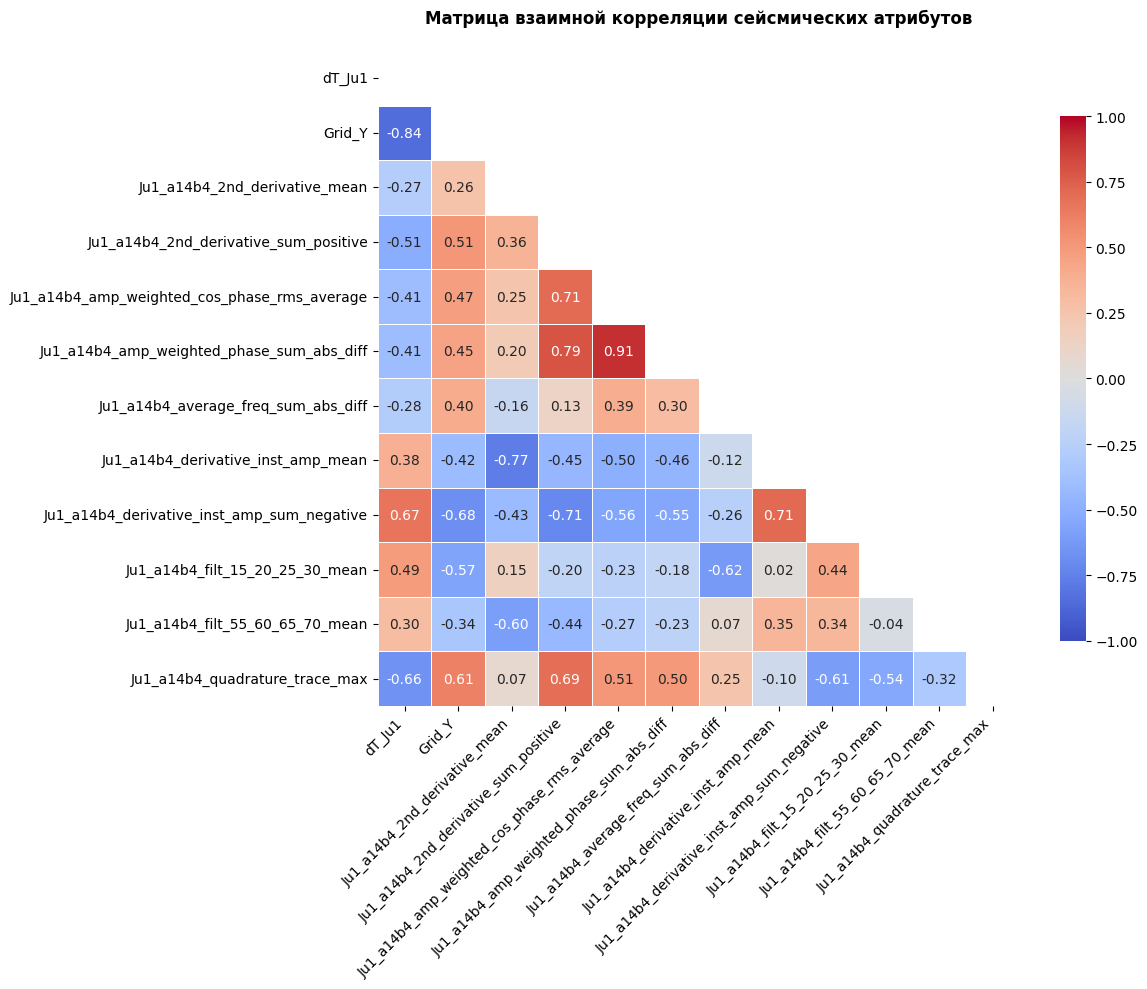

In [8]:
# Посмотрим на взаимную корреляцию оставшихся атрибутов

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Исключаем целевую переменную и координаты X, Y
columns_to_exclude = ['Heff', 'X', 'Y']
df_features = df_filtered.drop(columns=columns_to_exclude, errors='ignore')

# Рассчитываем матрицу линейной корреляции Пирсона между всеми атрибутами
corr_matrix = df_features.corr(method='pearson')

# Создаем маску для скрытия верхнего треугольника матрицы
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Строим график
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix, 
    mask=mask,
    cmap='coolwarm',
    vmax=1.0, vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

plt.title("Матрица взаимной корреляции сейсмических атрибутов", fontsize=12, pad=20, weight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()

plt.savefig('heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


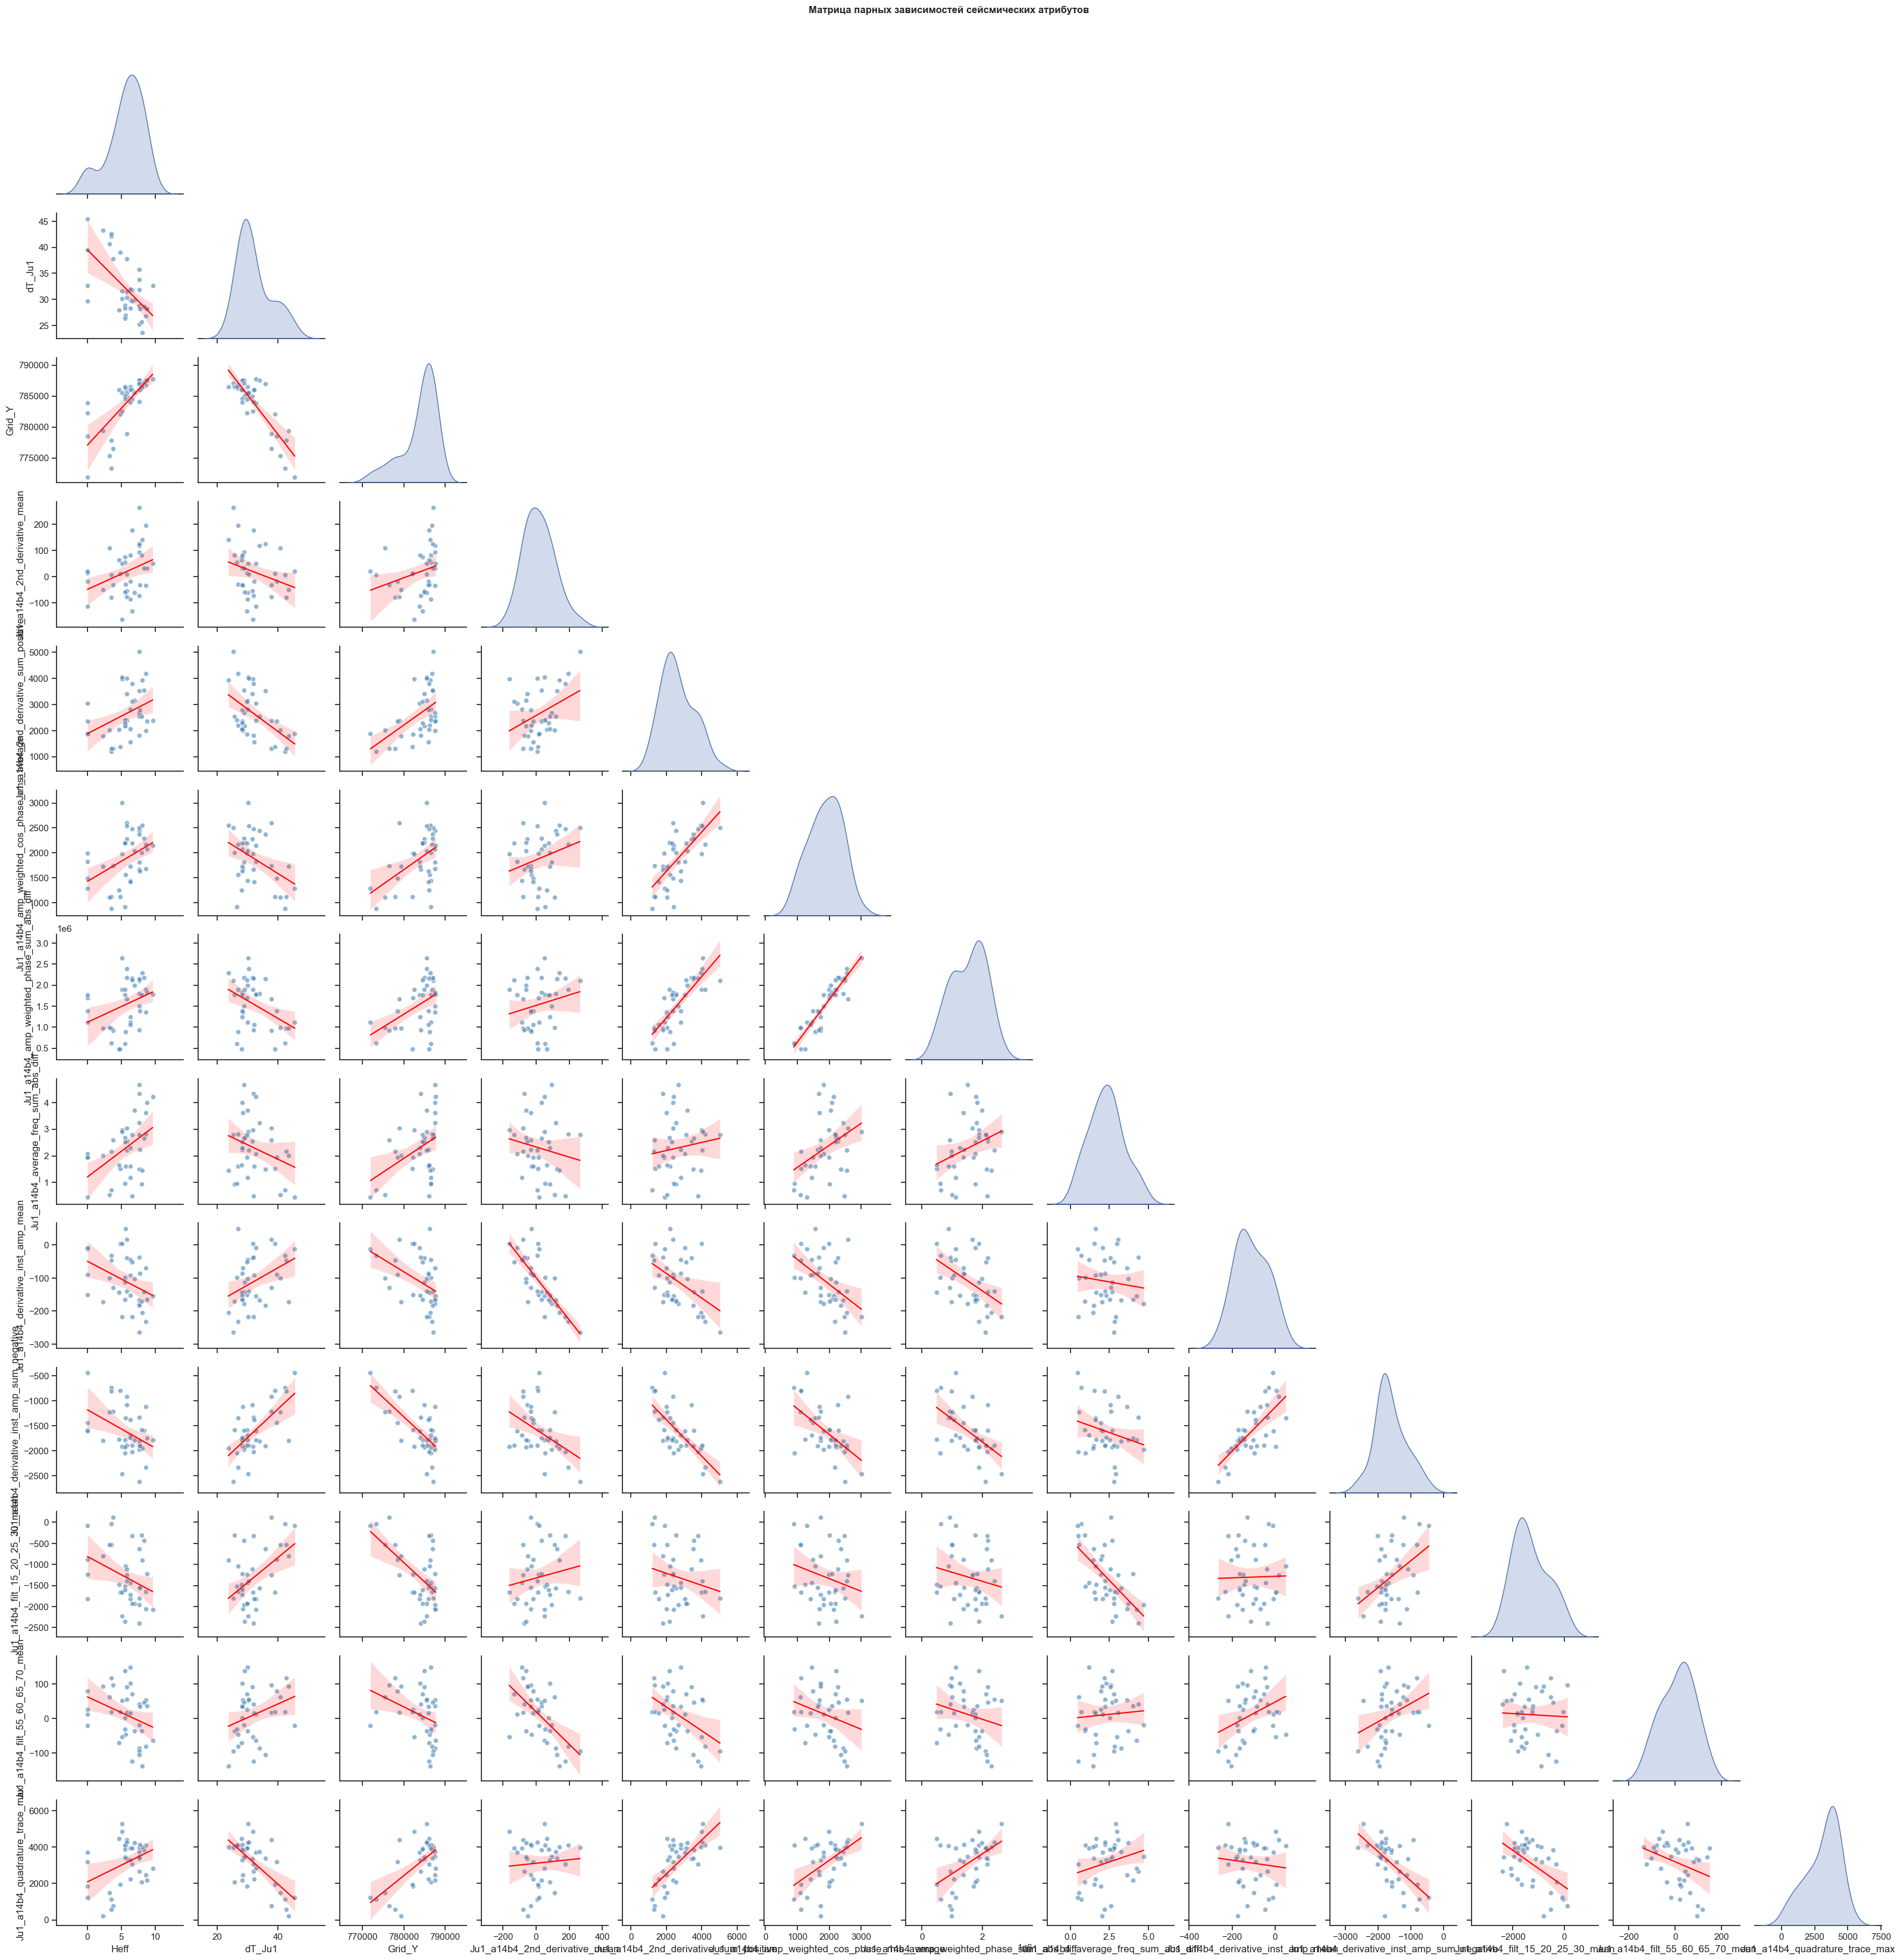

In [9]:
# Теперь посмотрим на графики попарной корреляции атрибутов между собой и с целевой переменной

columns_to_exclude = ['X', 'Y']
df_features = df_filtered.drop(columns=columns_to_exclude, errors='ignore')

# Строим pairplot
sns.set_theme(style="ticks")

g = sns.pairplot(
    df_features, 
    corner=True,
    kind='reg',
    diag_kind='kde',
    plot_kws={
        'scatter_kws': {'alpha': 0.6, 'color': 'steelblue', 'edgecolor': 'w'}, 
        'line_kws': {'color': 'red', 'linewidth': 1.5}
    }
)

g.fig.suptitle(
    "Матрица парных зависимостей сейсмических атрибутов", 
    fontsize=12, 
    weight='bold', 
    y=1.02
)

plt.savefig('correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


Строим графики сопоставления для 12 признаков.

Свод графиков сохранён в 'all_features_coverage_grid.png'


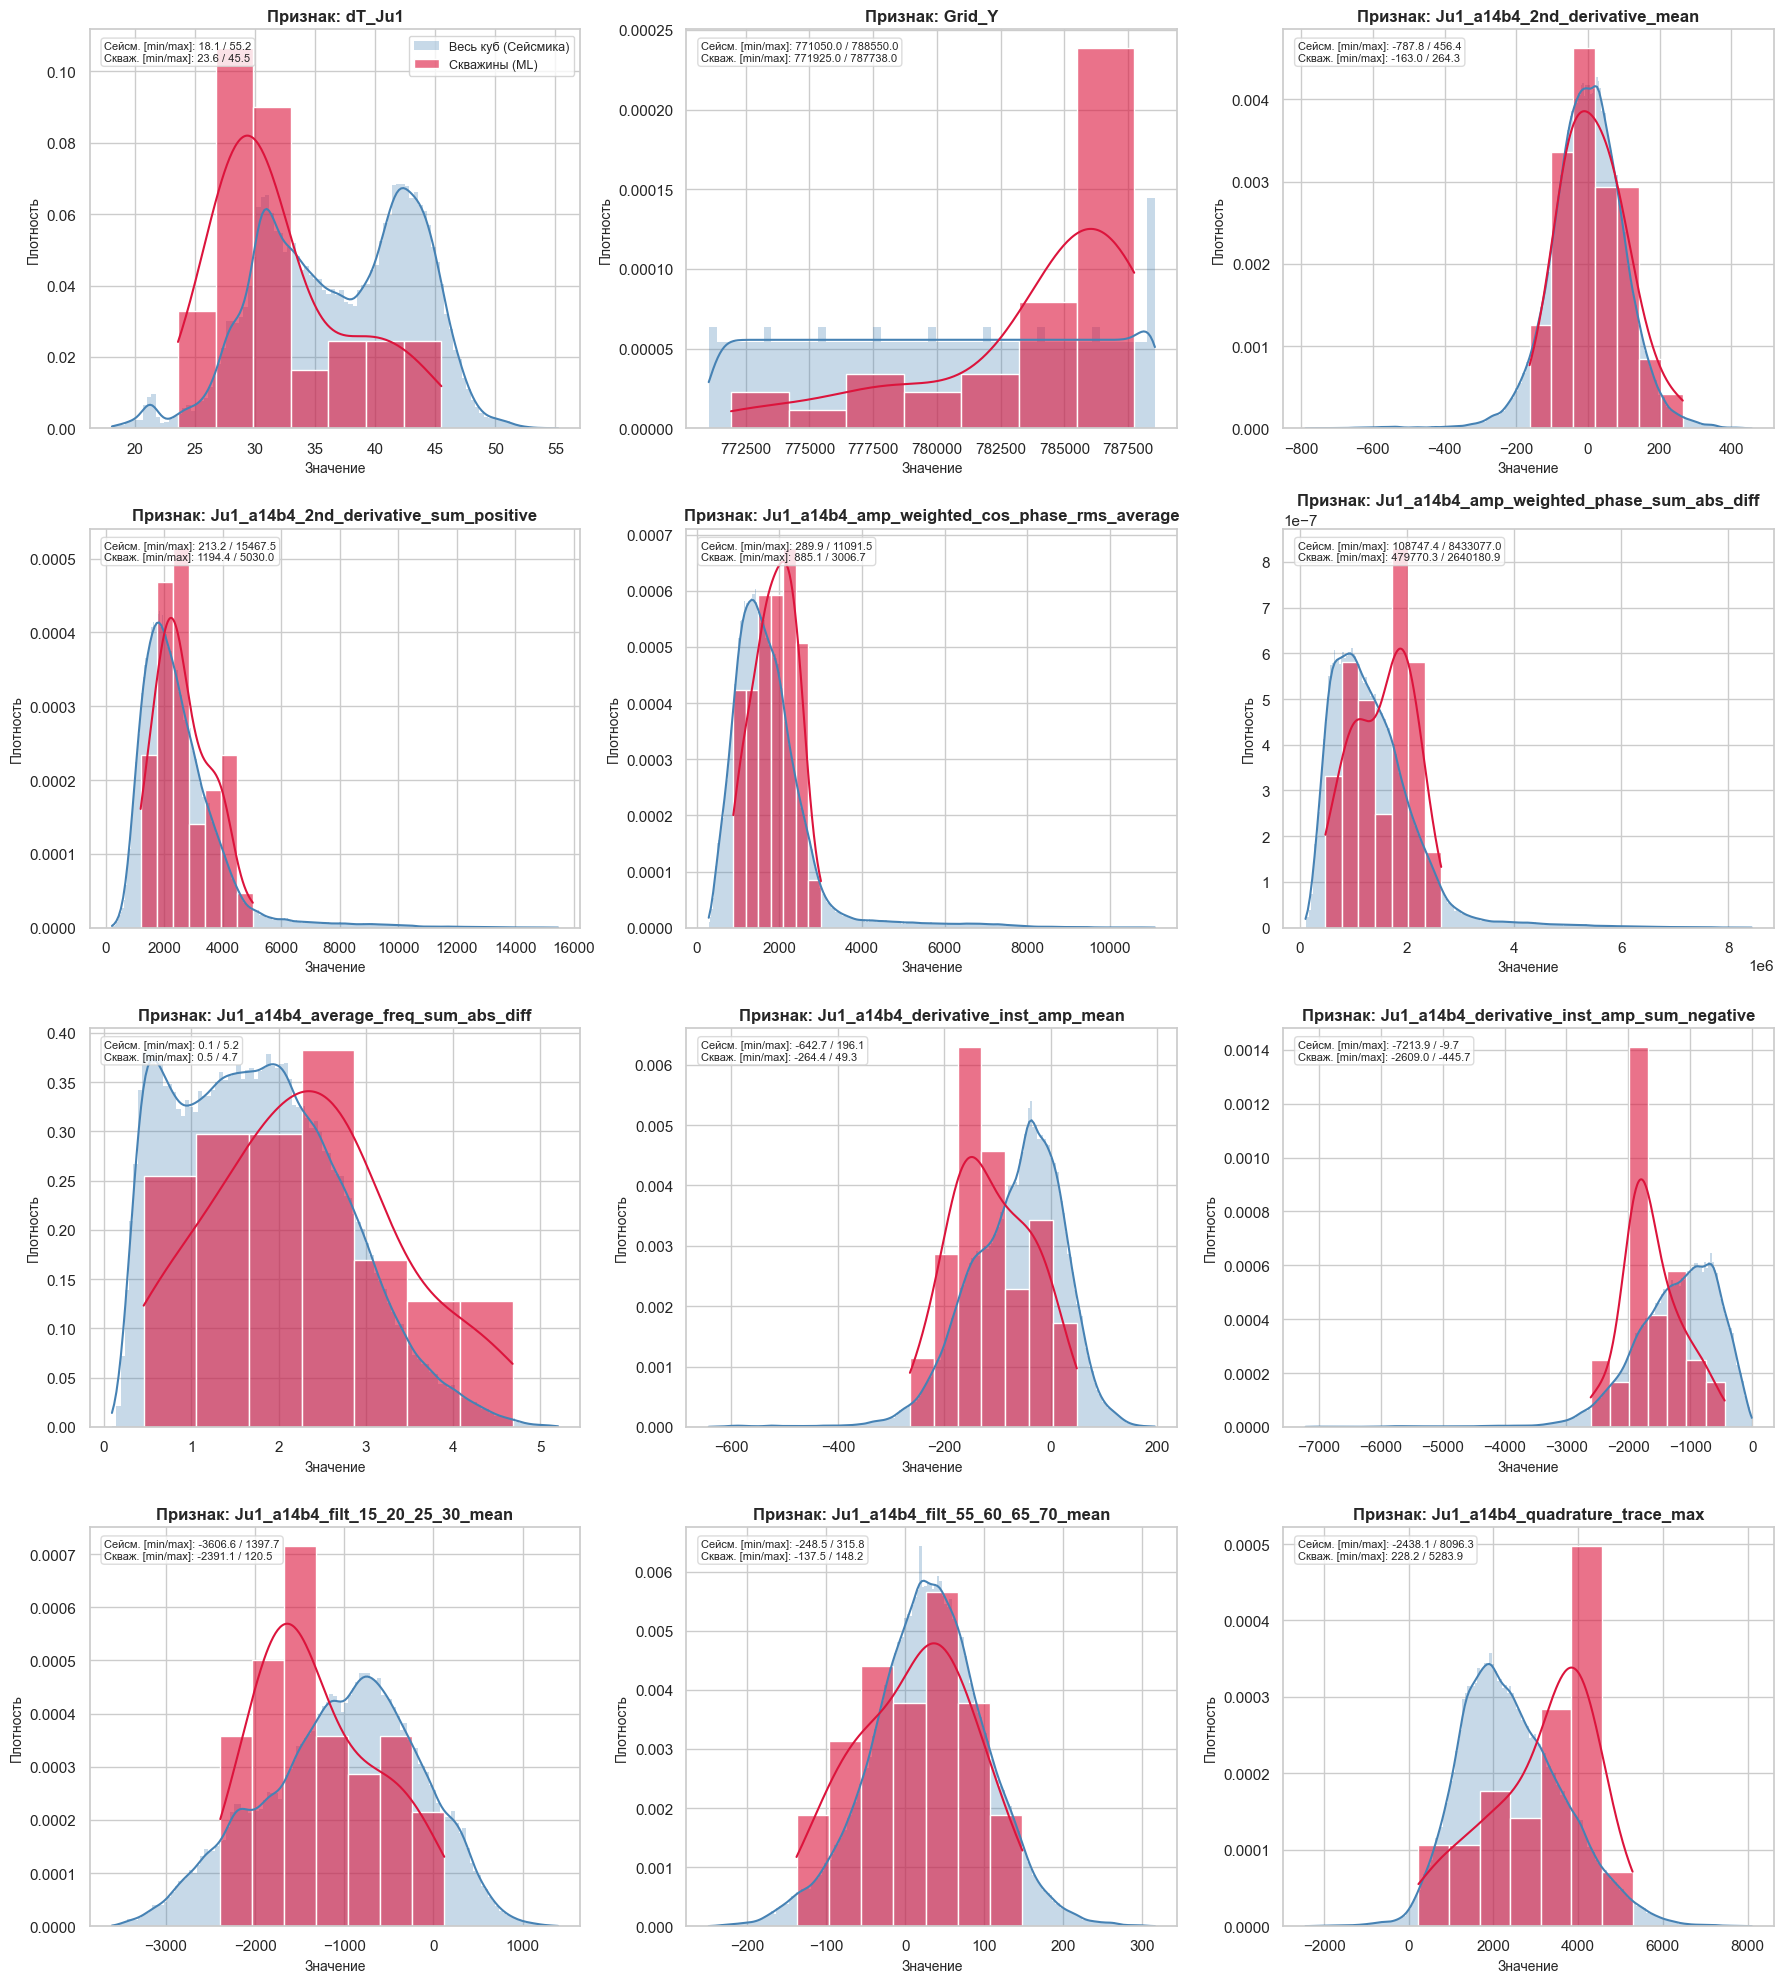

In [10]:
# Посмотрим на характер распределения атрибутов в точках скважин с полным массивом данных.

from functions_vizualization import plot_all_features_coverage
plot_all_features_coverage(df_filtered, target_col='Heff', data_slices_dir='./DATA_SLICES/')

График успешно сохранен в 'features_boxplot.png'


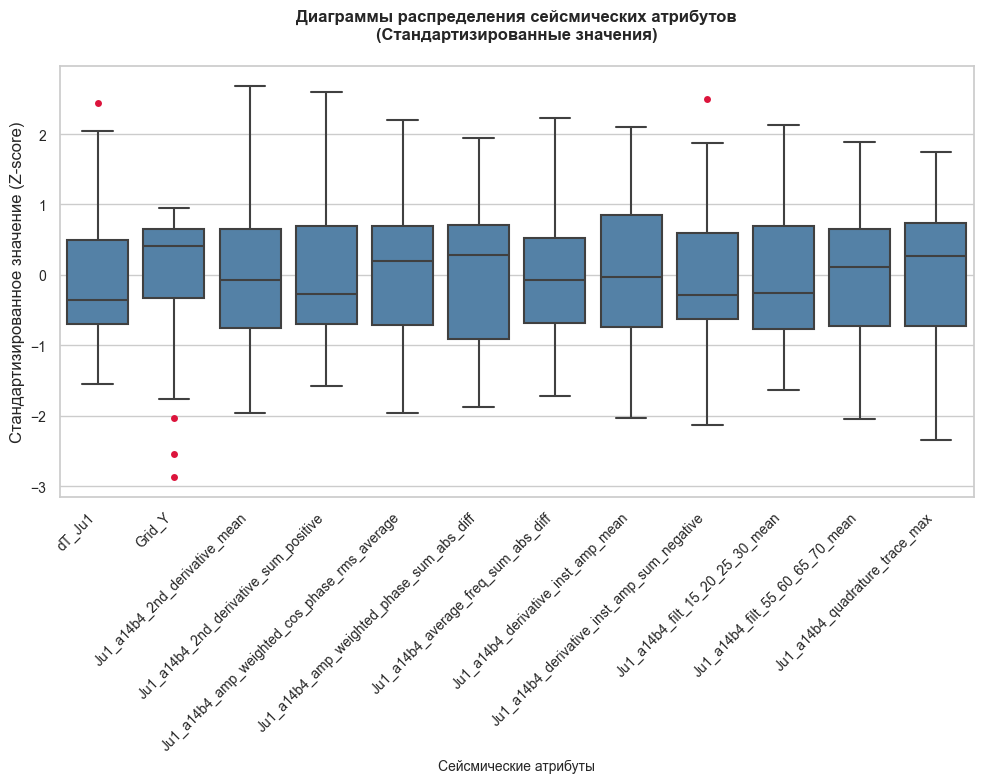

In [11]:
# Проверим данные на наличие выбросов

from sklearn.preprocessing import StandardScaler

# Готовим данные (исключаем координаты и целевую переменную Heff)
columns_to_exclude = ['Heff', 'X', 'Y']
df_features = df_filtered.drop(columns=columns_to_exclude, errors='ignore')

# Масштабируем признаки, чтобы их можно было наглядно сравнить на одном графике и превращаем обратно в DataFrame с сохранением названий колонок
scaler = StandardScaler()
scaled_matrix = scaler.fit_transform(df_features)
df_scaled = pd.DataFrame(scaled_matrix, columns=df_features.columns)

# Настраиваем стиль и размер графика
sns.set_theme(style="whitegrid")
plt.figure(figsize=(max(10, len(df_features.columns) * 0.8), 8))

# Строим ящики с усами
sns.boxplot(
    data=df_scaled, 
    color="steelblue",
    linewidth=1.5,
    fliersize=5,
    flierprops={"markerfacecolor": "crimson", "markeredgecolor": "none"} # Выбросы подсветим контрастным красным
)

plt.title(
    "Диаграммы распределения сейсмических атрибутов\n(Стандартизированные значения)", 
    fontsize=12, pad=20, weight='bold'
)
plt.ylabel("Стандартизированное значение (Z-score)", fontsize=12)
plt.xlabel("Сейсмические атрибуты", fontsize=10)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(fontsize=10)

plt.tight_layout()

# Сохраняем график в файл
output_box_path = "features_boxplot.png"
plt.savefig(output_box_path, dpi=300, bbox_inches='tight')

print(f"График успешно сохранен в '{output_box_path}'")
plt.show()


### Данные, подготовленные для обучения практически не содержат выбросов.

In [12]:
# Сохраняем подготовленный файл В CSV
# index=True сохранит колонку WellName как самый первый столбец
# encoding='utf-8-sig' предотвратит проблемы с кодировкой (если в названиях есть кириллица)

output_csv = 'wells_prepared_data.csv'
df_filtered.to_csv(output_csv, index=True, sep=';', encoding='utf-8-sig')